In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('CAR DETAILS FROM CAR DEKHO.csv')
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [4]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [6]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [8]:
df.shape

(4340, 8)

In [9]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [11]:
df.duplicated().sum()

np.int64(763)

In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df.shape

(3577, 8)

In [15]:
df.describe()

,year,selling_price,km_driven
count,3577.000000,3.577000e+03,3577.000000
mean,2012.962538,4.739125e+05,69250.545709
std,4.251759,5.093018e+05,47579.940016
min,1992.000000,2.000000e+04,1.000000
25%,2010.000000,2.000000e+05,36000.000000
50%,2013.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


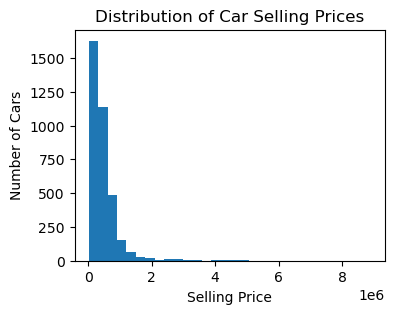

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 3))
plt.hist(df['selling_price'], bins=30)
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.title('Distribution of Car Selling Prices')
plt.show()

In [19]:
df['selling_price'].skew()

np.float64(5.453918181903924)

In [20]:
Q1 = df['selling_price'].quantile(0.25)
Q3 = df['selling_price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower)
print("Upper limit:", upper)

print("Potential outliers:",
      ((df['selling_price'] < lower) |
       (df['selling_price'] > upper)).sum())

Q1: 200000.0
Q3: 600000.0
IQR: 400000.0
Lower limit: -400000.0
Upper limit: 1200000.0
Potential outliers: 170


In [21]:
df.nlargest(10, 'selling_price')[
    ['name', 'year', 'selling_price', 'km_driven',
     'fuel', 'transmission']
]

,name,year,selling_price,km_driven,fuel,transmission
3872,Audi RS7 2015-2019 Sportback Performance,2016,8900000,13000,Petrol,Automatic
89,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500,Diesel,Automatic
3969,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,5500000,77350,Diesel,Automatic
555,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Automatic
3453,BMW 5 Series 520d Luxury Line,2018,4800000,9422,Diesel,Automatic
3883,BMW 5 Series 520d Luxury Line,2019,4800000,12999,Diesel,Automatic
963,Audi A5 Sportback,2020,4700000,1500,Diesel,Automatic
101,Mercedes-Benz E-Class Exclusive E 200 BSIV,2018,4500000,9800,Petrol,Automatic
4047,Volvo XC 90 D5 Inscription BSIV,2017,4500000,80000,Diesel,Automatic
539,Mercedes-Benz GL-Class 350 CDI Blue Efficiency,2014,4400000,100000,Diesel,Automatic


In [22]:
df['fuel'].value_counts()

fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

In [23]:
df['transmission'].value_counts()

transmission
Manual       3265
Automatic     312
Name: count, dtype: int64

In [24]:
df['seller_type'].value_counts()

seller_type
Individual          2832
Dealer               712
Trustmark Dealer      33
Name: count, dtype: int64

In [25]:
df['owner'].value_counts()

owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            17
Name: count, dtype: int64

In [26]:
print("Unique car names:", df['name'].nunique())

df['name'].head(10)

Unique car names: 1491


0                Maruti 800 AC
1     Maruti Wagon R LXI Minor
2         Hyundai Verna 1.6 SX
3       Datsun RediGO T Option
4        Honda Amaze VX i-DTEC
5         Maruti Alto LX BSIII
6    Hyundai Xcent 1.2 Kappa S
7     Tata Indigo Grand Petrol
8     Hyundai Creta 1.6 VTVT S
9     Maruti Celerio Green VXI
Name: name, dtype: object

In [27]:
from datetime import datetime

current_year = datetime.now().year

df['car_age'] = current_year - df['year']

df[['name', 'year', 'car_age']].head()

,name,year,car_age
0,Maruti 800 AC,2007,19
1,Maruti Wagon R LXI Minor,2007,19
2,Hyundai Verna 1.6 SX,2012,14
3,Datsun RediGO T Option,2017,9
4,Honda Amaze VX i-DTEC,2014,12


In [ ]:
df['car_age'].describe()

count    3577.000000
mean       13.037462
std         4.251759
min         6.000000
25%        10.000000
50%        13.000000
75%        16.000000
max        34.000000
Name: car_age, dtype: float64

In [9]:
categorical_cols = [
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


fuel:
fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

seller_type:
seller_type
Individual          2832
Dealer               712
Trustmark Dealer      33
Name: count, dtype: int64

transmission:
transmission
Manual       3265
Automatic     312
Name: count, dtype: int64

owner:
owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            17
Name: count, dtype: int64


In [10]:
X = df.drop('selling_price', axis=1)
y = df['selling_price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3577, 7)
y shape: (3577,)


In [11]:
print("Columns:", df.columns.tolist())
print("Duplicate rows:", df.duplicated().sum())

Columns: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
Duplicate rows: 0


In [12]:
from datetime import datetime

df['car_age'] = datetime.now().year - df['year']

df[['year', 'car_age']].head()

,year,car_age
0,2007,19
1,2007,19
2,2012,14
3,2017,9
4,2014,12


In [13]:
print(df.shape)
print(df.columns.tolist())

(3577, 9)
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'car_age']


In [14]:
X = df.drop('selling_price', axis=1)
y = df['selling_price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3577, 8)
y shape: (3577,)


In [26]:
from sklearn.model_selection import train_test_split

X = df.drop('selling_price', axis=1)
y = df['selling_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(2861, 8)
(716, 8)


In [27]:
X_train.dtypes

name            object
year             int64
km_driven        int64
fuel            object
seller_type     object
transmission    object
owner           object
car_age          int64
dtype: object

In [28]:
for col in X_train.select_dtypes(include='object').columns:
    print(col, ":", X_train[col].nunique())

name : 1306
fuel : 4
seller_type : 3
transmission : 2
owner : 5


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ['fuel', 'seller_type', 'transmission', 'owner']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

In [30]:
df['brand'] = df['name'].str.split().str[0]

df[['name', 'brand']].head(10)

,name,brand
0,Maruti 800 AC,Maruti
1,Maruti Wagon R LXI Minor,Maruti
2,Hyundai Verna 1.6 SX,Hyundai
3,Datsun RediGO T Option,Datsun
4,Honda Amaze VX i-DTEC,Honda
5,Maruti Alto LX BSIII,Maruti
6,Hyundai Xcent 1.2 Kappa S,Hyundai
7,Tata Indigo Grand Petrol,Tata
8,Hyundai Creta 1.6 VTVT S,Hyundai
9,Maruti Celerio Green VXI,Maruti


In [31]:
X = df.drop(columns=['selling_price', 'name'])
y = df['selling_price']

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.columns.tolist())

X shape: (3577, 8)
y shape: (3577,)
['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'car_age', 'brand']


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2861, 8)
X_test: (716, 8)
y_train: (2861,)
y_test: (716,)
